In [32]:
from langgraph.graph import StateGraph, START ,END
from typing import TypedDict,Literal

In [33]:
class Quad(TypedDict):
    a:int
    b:int
    c:int

    equation:str
    discriminant:int
    result:str

In [34]:
def Show_Equation(state:Quad):
    equation=f"{state['a']}x2+{state['b']}x+{state['c']}=0"
    return {"equation":equation}

def Calculate_Discriminant(state:Quad):
    discriminant=state['b']**2-(4*state['a']*state['c'])
    return {"discriminant":discriminant}

def real_roots(state:Quad):
    root1=(-state['b']+(state['b']**2-(4*state['a']*state['c'])))/(2*state['a'])
    root2=(-state['b']-(state['b']**2-(4*state['a']*state['c'])))/(2*state['a'])
    return {"result":f"The roots are real and they are {root1} and {root2}"}

def repeating_roots(state:Quad):
    root=(-state['b'])/(2*state['a'])
    return {"result":f"The root is repeating and it is {root}"}

def no_roots(state:Quad):
    return {"result":f"The equation has no real roots"}

In [35]:
def check_condition(state:Quad)->Literal["real_roots","repeating_roots","no_roots"]:
    discriminant=state['discriminant']
    if discriminant>0:
        return "real_roots"
    elif discriminant==0:
        return "repeating_roots"
    else:
        return "no_roots"

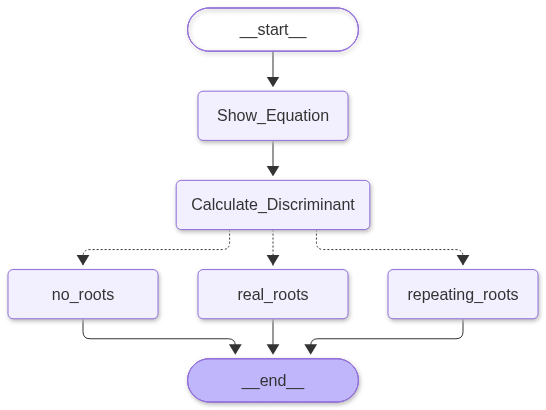

In [36]:
graph=StateGraph(Quad)

graph.add_node("Show_Equation",Show_Equation)
graph.add_node("Calculate_Discriminant",Calculate_Discriminant)
graph.add_node("real_roots",real_roots)
graph.add_node("repeating_roots",repeating_roots)
graph.add_node("no_roots",no_roots)

graph.add_edge(START,"Show_Equation")
graph.add_edge("Show_Equation","Calculate_Discriminant")
graph.add_conditional_edges("Calculate_Discriminant",check_condition)
graph.add_edge("real_roots",END)
graph.add_edge("repeating_roots",END)
graph.add_edge("no_roots",END)

workflow=graph.compile()
workflow

In [39]:
initial_state={"a":4,"b":2,"c":4}
final_state=workflow.invoke(initial_state)

In [40]:
final_state

{'a': 4,
 'b': 2,
 'c': 4,
 'equation': '4x2+2x+4=0',
 'discriminant': -60,
 'result': 'The equation has no real roots'}